# 01 — Exploratory Data Analysis: SeasoNet (Summer + Snow)

Goal: understand the SeasoNet data we use and record every cleaning decision before training.

We use only the **Summer** and **Snow** subsets. Each tile is a 1.2 km × 1.2 km Sentinel-2 patch over Germany.

Data lives outside the repo. See the README for download steps. The notebook reads from `../data` (a symlink), or from the `SEASONET_DIR` environment variable if set.

In [2]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tifffile
from scipy.spatial import KDTree
from omegaconf import OmegaConf

REPO_DIR = Path.cwd()
if not (REPO_DIR / "src").is_dir():
    REPO_DIR = REPO_DIR.parent
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

from src.preprocessing.data_cleaner import load_pairs
from src.preprocessing.normalization import normalize_rgb
from src.preprocessing.spatial import haversine_distance_m, lon_lat_to_unit_sphere
from src.preprocessing.splits import assign_geographic_splits

DATA_DIR = Path(os.environ.get("SEASONET_DIR", REPO_DIR / "data")).resolve()
PREPROCESSING_CFG = OmegaConf.load(REPO_DIR / "config/preprocessing_config.yaml")
MAX_CLOUD_COVER = PREPROCESSING_CFG.cleaning.max_cloud_cover
SEASONS = ["Summer", "Snow"]
assert (DATA_DIR / "meta.csv").exists(), f"meta.csv not found in {DATA_DIR}"

## 1. Metadata overview

In [3]:
meta = pd.read_csv(DATA_DIR / "meta.csv")
print(meta.shape)
meta.head()

(1759830, 19)


,Index,Season,Grid,Latitude,Longitude,Satellite,Year,Month,Day,Hour,Minute,Second,Clouds,Snow,Classes,SLRAUM,RTYP3,KTYP4,Path
0,0,Spring,1,53.928425,7.503876,A,2018,4,18,10,40,21,0.0,0.0,33,0,0,0,spring/grid1/32UME_20180418T104021_53_928425_7...
1,1,Spring,1,48.207815,11.226377,B,2018,5,7,10,20,19,0.0,0.0,"2,3,12,15,17",1,1,2,spring/grid1/32UPU_20180507T102019_48_207815_1...
2,2,Spring,1,52.498670,8.472121,A,2018,5,8,10,40,31,0.0,0.0,"12,15,16,18",2,2,3,spring/grid1/32UMD_20180508T104031_52_498670_8...
3,3,Spring,1,52.356133,7.164578,A,2018,4,18,10,40,21,0.0,0.0,"12,15,17,18,21",2,3,4,spring/grid1/32ULD_20180418T104021_52_356133_7...
4,4,Spring,1,51.345605,14.158105,A,2018,4,9,10,10,31,0.0,0.0,"12,15,16,17,30",2,3,3,spring/grid1/33UVS_20180409T101031_51_345605_1...


In [4]:
meta["Season"].value_counts()

Season
Fall      500149
Summer    481456
Spring    460104
Winter    218663
Snow       99458
Name: count, dtype: int64

`meta.csv` covers all five seasons. We drop Spring, Fall and Winter.

In [5]:
df = meta[meta["Season"].isin(SEASONS)].copy()
df["loc_id"] = df["Grid"].astype(str) + "_" + df["Latitude"].map("{:.6f}".format) + "_" + df["Longitude"].map("{:.6f}".format)
df.groupby("Season").agg(rows=("Index", "size"), unique_locations=("loc_id", "nunique"), years=("Year", "unique"))

,rows,unique_locations,years
Season,,,
Snow,99458,99458,[2019]
Summer,481456,481456,[2018]


## 2. Summer ↔ Snow pairing

Contrastive training needs the same location in both seasons. A location is identified by grid + tile centre coordinates.

In [6]:
per_loc = df.pivot_table(index="loc_id", columns="Season", values="Index", aggfunc="count", fill_value=0)
print("max images per location per season:", per_loc.max().to_dict())
print("locations with both seasons:", int(((per_loc["Summer"] > 0) & (per_loc["Snow"] > 0)).sum()))
print("summer-only locations:", int(((per_loc["Summer"] > 0) & (per_loc["Snow"] == 0)).sum()))
print("snow-only locations:", int(((per_loc["Summer"] == 0) & (per_loc["Snow"] > 0)).sum()))

max images per location per season: {'Snow': 1, 'Summer': 1}
locations with both seasons: 83739
summer-only locations: 397717
snow-only locations: 15719


In [7]:
pairs = load_pairs(DATA_DIR, max_cloud_cover=MAX_CLOUD_COVER)
print(len(pairs), "pairs")
pairs[["loc_id", "Path_summer", "Path_snow", "Clouds_summer", "Clouds_snow", "Snow_snow"]].head()

80897 pairs


,loc_id,Path_summer,Path_snow,Clouds_summer,Clouds_snow,Snow_snow
0,1_14.158105_51.345605,summer/grid1/33UVS_20180807T101021_51_345605_1...,snow/grid1/33UVS_20190208T101159_51_345605_14_...,0.000,1.139,50.944
1,1_12.038731_47.656843,summer/grid1/32TQT_20180731T102021_47_656843_1...,snow/grid1/32TQT_20190228T101029_47_656843_12_...,0.028,1.694,63.611
2,1_12.206240_48.814694,summer/grid1/32UQV_20180703T101029_48_814694_1...,snow/grid1/32UQV_20190213T101131_48_814694_12_...,0.000,30.861,21.056
3,1_10.627042_47.642372,summer/grid1/32TPT_20180616T102019_47_642372_1...,snow/grid1/32TPT_20190221T102039_47_642372_10_...,0.000,4.028,94.333
4,1_12.245605_49.169897,summer/grid1/32UQV_20180703T101029_49_169897_1...,snow/grid1/32UQV_20190213T101131_49_169897_12_...,0.028,29.194,34.722


## 3. Cloud and snow coverage (paired tiles)

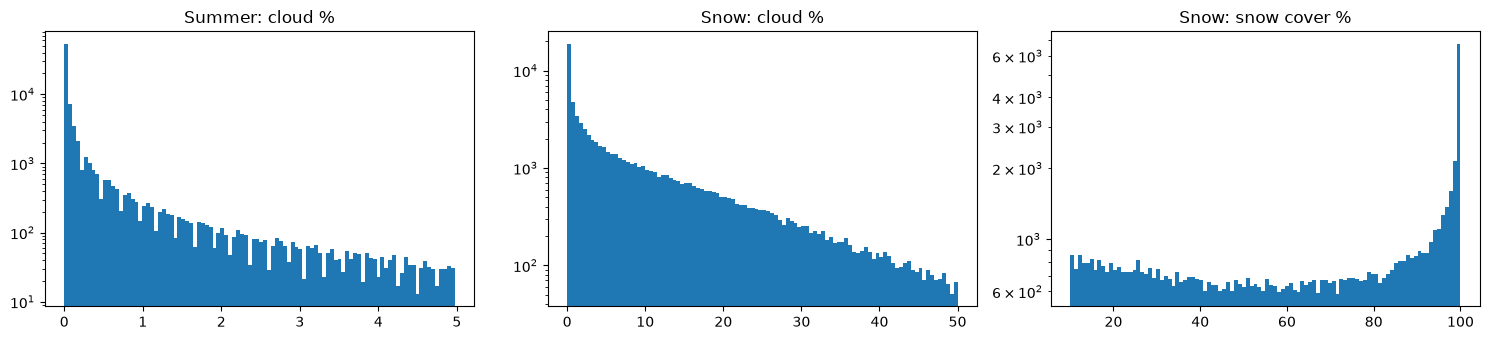

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
axes[0].hist(pairs["Clouds_summer"], bins=100); axes[0].set_title("Summer: cloud %")
axes[1].hist(pairs["Clouds_snow"], bins=100); axes[1].set_title("Snow: cloud %")
axes[2].hist(pairs["Snow_snow"], bins=100); axes[2].set_title("Snow: snow cover %")
for ax in axes: ax.set_yscale("log")
plt.tight_layout()

In [9]:
for col in ["Clouds_summer", "Clouds_snow", "Snow_snow"]:
    print(col, pairs[col].describe(percentiles=[.5, .9, .99]).round(2).to_dict())
for t in [1, 5, 10, 25]:
    print(f"pairs with snow-season clouds <= {t}%:", int((pairs["Clouds_snow"] <= t).sum()))
for t in [30, 40, 50]:
    print(f"pairs with snow-season clouds > {t}%:", int((pairs["Clouds_snow"] > t).sum())) 

Clouds_summer {'count': 80897.0, 'mean': 0.24, 'std': 0.67, 'min': 0.0, '50%': 0.0, '90%': 0.67, '99%': 3.75, 'max': 4.97}
Clouds_snow {'count': 80897.0, 'mean': 9.06, 'std': 10.89, 'min': 0.0, '50%': 4.61, '90%': 25.5, '99%': 44.61, 'max': 50.0}
Snow_snow {'count': 80897.0, 'mean': 60.61, 'std': 29.07, 'min': 10.0, '50%': 62.47, '90%': 98.57, '99%': 100.0, 'max': 100.0}
pairs with snow-season clouds <= 1%: 23833
pairs with snow-season clouds <= 5%: 41742
pairs with snow-season clouds <= 10%: 53865
pairs with snow-season clouds <= 25%: 72448
pairs with snow-season clouds > 30%: 5373
pairs with snow-season clouds > 40%: 1809
pairs with snow-season clouds > 50%: 0


## 4. Geographic coverage

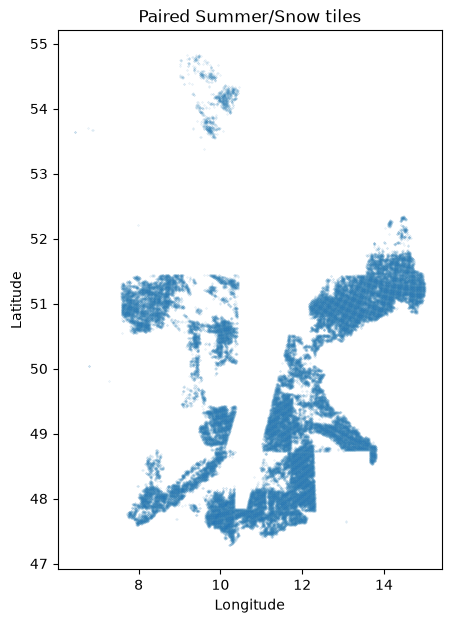

In [10]:
fig, ax = plt.subplots(figsize=(6, 7))
ax.scatter(pairs["Longitude_summer"], pairs["Latitude_summer"], s=0.05, alpha=0.3)
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude"); ax.set_title("Paired Summer/Snow tiles")
ax.set_aspect(1 / np.cos(np.deg2rad(51)))

## 5. Tile format

Each tile folder holds several files. We expect to use `*_10m_RGB.tif` as DINOv2 input.

In [11]:
sample_dir = DATA_DIR / pairs.iloc[0]["Path_snow"]
for f in sorted(sample_dir.iterdir()):
    if f.suffix == ".tif":
        a = tifffile.imread(f)
        print(f"{f.name.split('_', 6)[-1]:<18} shape={a.shape!s:<14} dtype={a.dtype} range=[{a.min()}, {a.max()}]")

10m_IR.tif         shape=(120, 120)     dtype=uint16 range=[381, 9360]
10m_RGB.tif        shape=(120, 120, 3)  dtype=uint16 range=[0, 10017]
20m.tif            shape=(60, 60, 6)    dtype=uint16 range=[39, 10409]
60m.tif            shape=(20, 20, 2)    dtype=uint16 range=[0, 9120]
clouds.tif         shape=(120, 120)     dtype=bool range=[False, True]
labels.tif         shape=(120, 120)     dtype=uint8 range=[12, 30]
mask_easy.tif      shape=(120, 120)     dtype=bool range=[False, True]
mask_medium.tif    shape=(120, 120)     dtype=bool range=[False, True]
snow.tif           shape=(120, 120)     dtype=bool range=[False, True]


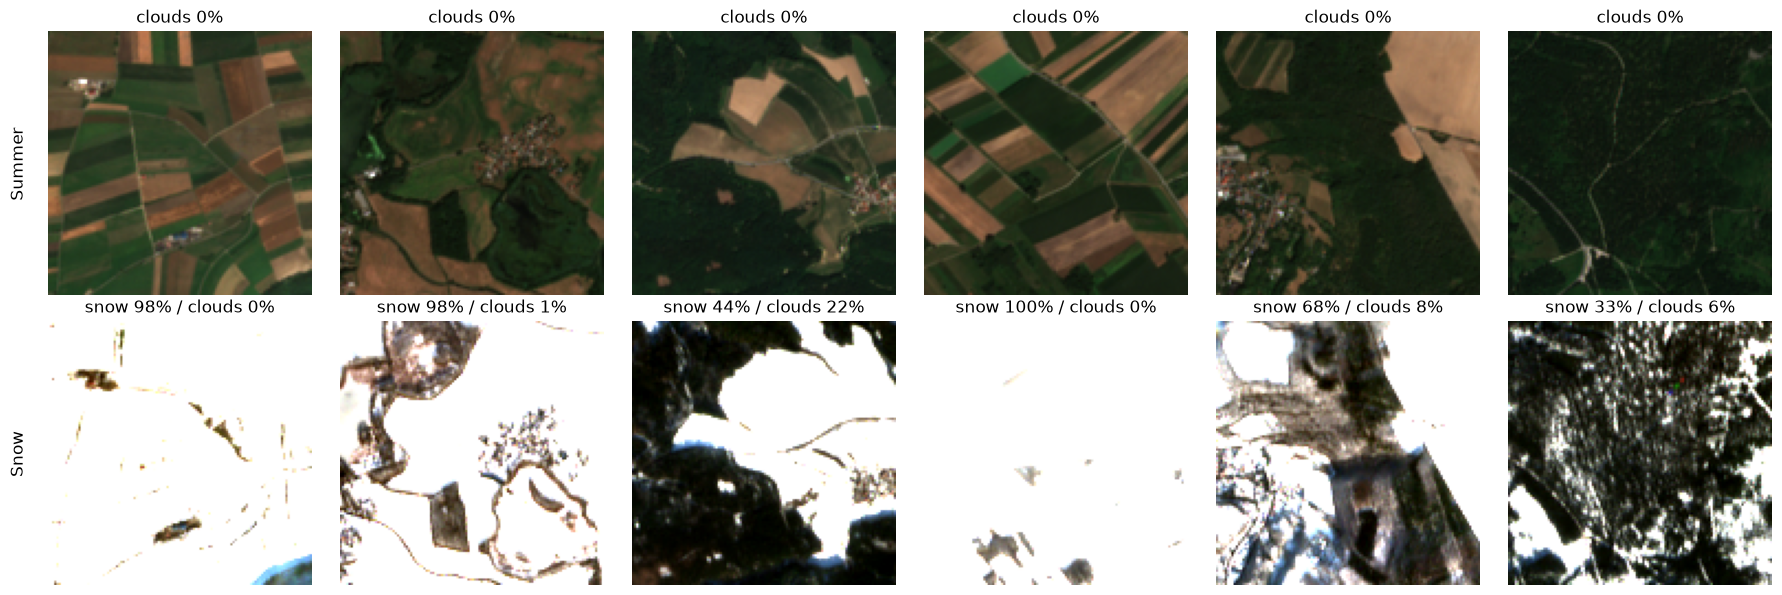

In [12]:
def load_rgb(rel_path):
    p = DATA_DIR / rel_path
    return tifffile.imread(next(p.glob("*_10m_RGB.tif")))

def to_display(rgb, lo=0, hi=3000):
    return np.clip((rgb.astype(np.float32) - lo) / (hi - lo), 0, 1)

show = pairs.sample(6, random_state=0)
fig, axes = plt.subplots(2, 6, figsize=(18, 6))
for j, (_, r) in enumerate(show.iterrows()):
    axes[0, j].imshow(to_display(load_rgb(r["Path_summer"])))
    axes[1, j].imshow(to_display(load_rgb(r["Path_snow"])))
    axes[0, j].set_title(f"clouds {r['Clouds_summer']:.0f}%")
    axes[1, j].set_title(f"snow {r['Snow_snow']:.0f}% / clouds {r['Clouds_snow']:.0f}%")
    for ax in axes[:, j]: ax.axis("off")
axes[0, 0].text(-10, 60, "Summer", rotation=90, va="center", ha="right", fontsize=12)
axes[1, 0].text(-10, 60, "Snow", rotation=90, va="center", ha="right", fontsize=12)
plt.tight_layout()

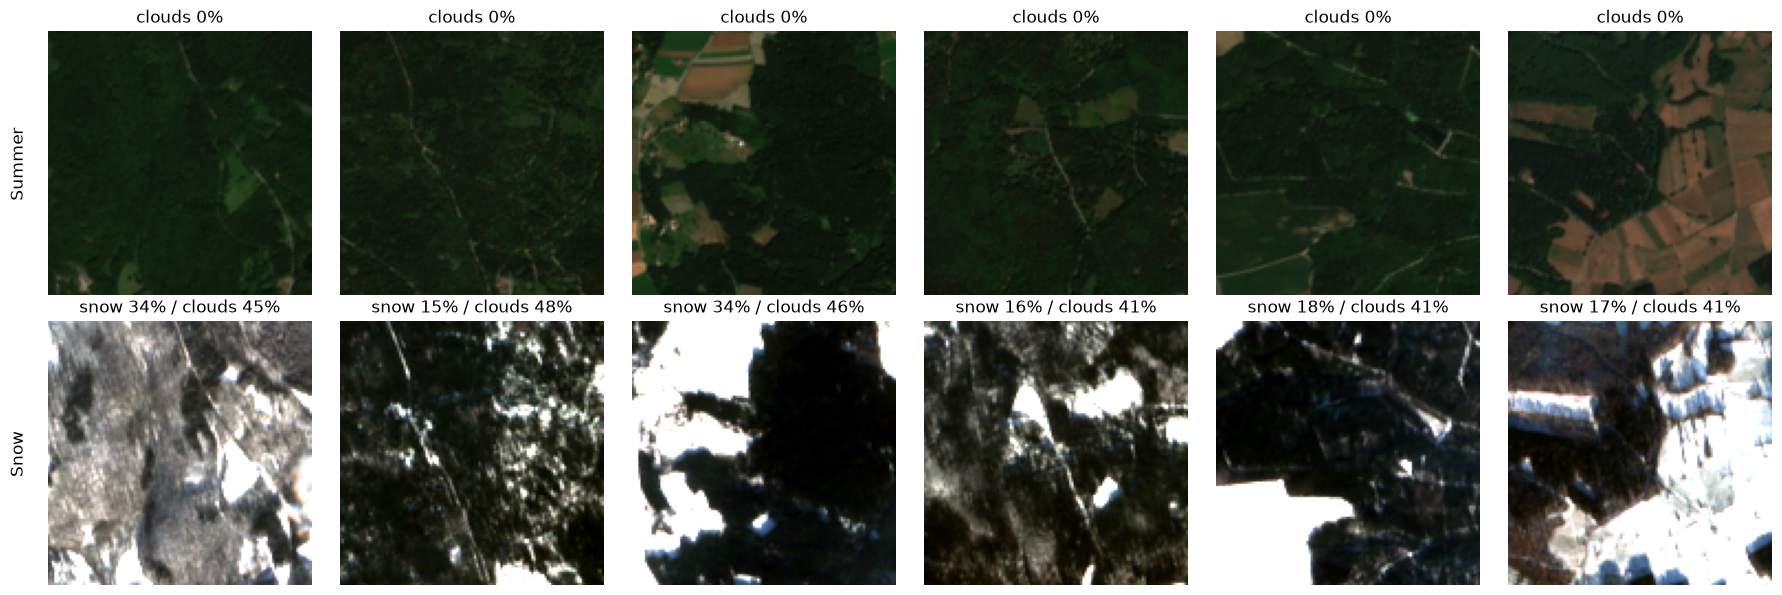

In [13]:
PERCENTAGE = 40
high_cloud_pairs = pairs[pairs["Clouds_snow"] > PERCENTAGE]

if high_cloud_pairs.empty:
    print(f"No pairs have Snow cloud coverage above {PERCENTAGE}%.")
else:
    show = high_cloud_pairs.sample(min(6, len(high_cloud_pairs)))
    fig, axes = plt.subplots(2, 6, figsize=(18, 6))
    for j, (_, r) in enumerate(show.iterrows()):
        axes[0, j].imshow(to_display(load_rgb(r["Path_summer"])))
        axes[1, j].imshow(to_display(load_rgb(r["Path_snow"])))
        axes[0, j].set_title(f"clouds {r['Clouds_summer']:.0f}%")
        axes[1, j].set_title(f"snow {r['Snow_snow']:.0f}% / clouds {r['Clouds_snow']:.0f}%")
        for ax in axes[:, j]: ax.axis("off")
    axes[0, 0].text(-10, 60, "Summer", rotation=90, va="center", ha="right", fontsize=12)
    axes[1, 0].text(-10, 60, "Snow", rotation=90, va="center", ha="right", fontsize=12)
    plt.tight_layout()

## 6. Pixel intensity by season

Values are uint16 surface reflectance. Snow tiles are much brighter, so normalization needs care.

,Summer,Snow
mean,"[636.0, 663.0, 417.0]","[3630.0, 3598.0, 3598.0]"
std,"[548.0, 364.0, 297.0]","[3286.0, 3261.0, 3360.0]"
p99,"[2512.0, 1848.0, 1356.0]","[9967.0, 9848.0, 10000.0]"


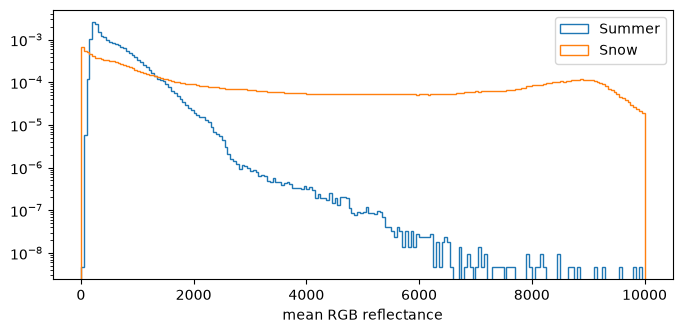

In [14]:
sub = pairs.sample(300, random_state=1)
stats = {s: np.stack([load_rgb(p).reshape(-1, 3) for p in sub[f"Path_{s.lower()}"]]).reshape(-1, 3) for s in SEASONS}
fig, ax = plt.subplots(figsize=(8, 3.5))
for s, px in stats.items():
    ax.hist(px.mean(axis=1), bins=200, range=(0, 10000), histtype="step", density=True, label=s)
ax.set_xlabel("mean RGB reflectance"); ax.legend(); ax.set_yscale("log")
pd.DataFrame({s: {"mean": px.mean(0).round(0).tolist(), "std": px.std(0).round(0).tolist(), "p99": np.percentile(px, 99, axis=0).round(0).tolist()} for s, px in stats.items()})

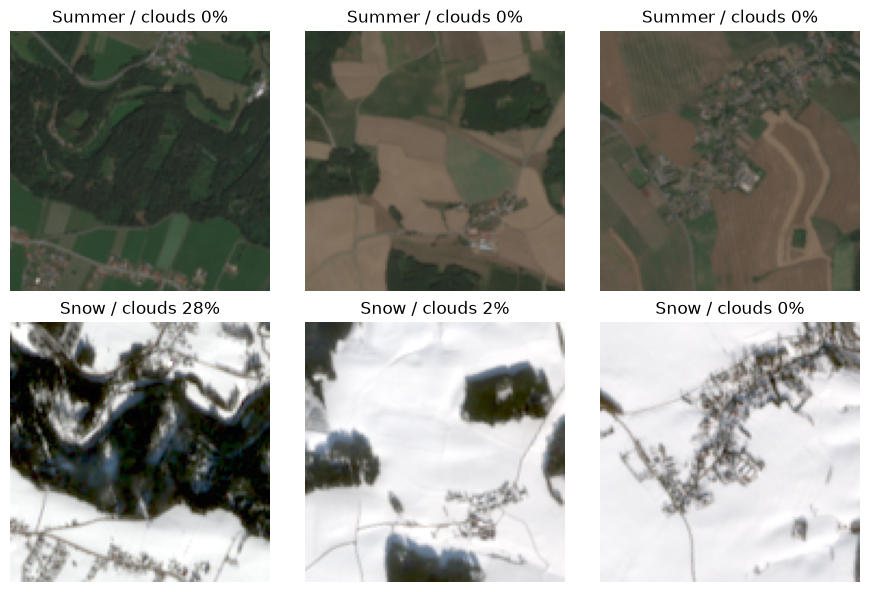

In [15]:
show = pairs.sample(3, random_state=2)
fig, axes = plt.subplots(2, 3, figsize=(9, 6))
for j, (_, r) in enumerate(show.iterrows()):
    axes[0, j].imshow(normalize_rgb(load_rgb(r["Path_summer"])))
    axes[1, j].imshow(normalize_rgb(load_rgb(r["Path_snow"])))
    axes[0, j].set_title(f"Summer / clouds {r['Clouds_summer']:.0f}%")
    axes[1, j].set_title(f"Snow / clouds {r['Clouds_snow']:.0f}%")
    for ax in axes[:, j]:
        ax.axis("off")

plt.tight_layout()

## 7. Geographic splits

We assign whole 10 km geographic blocks to train, validation, or test, then drop pairs within a 2 km cross-split buffer.

This prevents overlapping Grid 1/Grid 2 tiles from crossing splits.

In [16]:
ps = assign_geographic_splits(pairs)
print(ps["split"].value_counts())

split
train    56672
test     16121
val       8104
Name: count, dtype: int64


In [17]:
lat = ps["Latitude_summer"].values
lon = ps["Longitude_summer"].values
xyz = lon_lat_to_unit_sphere(lon, lat)
train = ps["split"].values == "train"
test = ps["split"].values == "test"
_, nearest_indices = KDTree(xyz[train]).query(xyz[test])
dist = haversine_distance_m(
    lon[test], lat[test],
    lon[train][nearest_indices], lat[train][nearest_indices],
)
print("test tile -> nearest train tile (m):", np.percentile(dist, [10, 50, 90]).round(0))
print("share of test tiles overlapping a train tile (< 1200 m):", (dist < 1200).mean().round(3))

test tile -> nearest train tile (m): [847. 847. 848.]
share of test tiles overlapping a train tile (< 1200 m): 0.987


**Finding:** the geographic buffer keeps overlapping tiles out of different splits.

## 8. Data integrity (sample of 2,000 pairs)

Checks for missing or malformed files, duplicates, misaligned pairs, no-data pixels and saturated pixels. Rerun on the full paired set before training.

In [18]:
mgrs = lambda p: p.split("/")[-1][:5]
print("pairs from different MGRS tiles:", int((pairs["Path_summer"].map(mgrs) != pairs["Path_snow"].map(mgrs)).sum()))

def tile_checks(rel_path):
    d = DATA_DIR / rel_path
    f = next(d.glob("*_10m_RGB.tif"), None)
    if f is None:
        return None
    with tifffile.TiffFile(f) as t:
        a = t.asarray()
        tie = t.pages[0].tags["ModelTiepointTag"].value
    meta_json = pd.read_json(next(d.glob("*_meta.json")), typ="series")
    return {
        "shape_ok": a.shape == (120, 120, 3),
        "nodata_frac": (a == 0).all(-1).mean(),
        "saturated_frac": (a >= 10000).any(-1).mean(),
        "md5": pd.util.hash_array(a.ravel()).sum(),
        "tiepoint": tie,
        "json_cloud_pct": meta_json["cloud_pct"],
    }

sample = pairs.sample(2000, random_state=0)
rows = []
for _, r in sample.iterrows():
    for s in SEASONS:
        c = tile_checks(r[f"Path_{s.lower()}"])
        rows.append({"loc_id": r["loc_id"], "season": s, "missing": c is None, "meta_clouds": r[f"Clouds_{s.lower()}"], **(c or {})})
chk = pd.DataFrame(rows)

tie_mismatch = chk.pivot(index="loc_id", columns="season", values="tiepoint").apply(lambda r: r["Summer"] != r["Snow"], axis=1).sum()
print("missing RGB:", int(chk["missing"].sum()), "| bad shape:", int((~chk["shape_ok"]).sum()), "| duplicate images:", int(chk["md5"].duplicated().sum()))
print("pairs with misaligned georeference:", int(tie_mismatch))
print("max |meta.csv Clouds - tile json cloud_pct|:", round((chk["meta_clouds"] - chk["json_cloud_pct"]).abs().max(), 3))

pairs from different MGRS tiles: 0
missing RGB: 0 | bad shape: 0 | duplicate images: 0
pairs with misaligned georeference: 0
max |meta.csv Clouds - tile json cloud_pct|: 0.0


In [19]:
chk.groupby("season").agg(
    any_nodata=("nodata_frac", lambda x: (x > 0).mean()),
    nodata_over_5pct=("nodata_frac", lambda x: (x > 0.05).mean()),
    max_nodata=("nodata_frac", "max"),
    any_saturated=("saturated_frac", lambda x: (x > 0).mean()),
    mean_saturated_when_present=("saturated_frac", lambda x: x[x > 0].mean()),
).round(4)

,any_nodata,nodata_over_5pct,max_nodata,any_saturated,mean_saturated_when_present
season,,,,,
Snow,0.174,0.0,0.0151,0.6025,0.0184
Summer,0.000,0.0,0.0000,0.0320,0.0003


## 9. Findings and cleaning decisions

Fill in as the team decides. Each decision should be backed by a cell above.

| # | Issue | Decision | Status |
|---|---|---|---|
| 1 | `meta.csv` includes Spring/Fall/Winter | Keep Summer + Snow only. Filtered in code (section 1); raw `meta.csv` is unchanged | done |
| 2 | Not every location has both seasons | Train on paired locations; summer-only tiles may be retrieval distractors | open |
| 3 | Snow tiles can be very cloudy (median 5%, max 90%) | Pick a max cloud % threshold for training using zero-shot recall by cloud level; keep `Clouds` as a column. Per-pixel `_clouds.tif` masks exist if needed | open |
| 4 | ~10% of snow tiles are ≥98% snow (almost blank) | Pick a max snow % threshold, or keep for eval only and report recall by snow % | open |
| 5 | Official splits leak spatially (overlapping grids) | Spatial block split; keep overlapping tiles in the same split | open |
| 6 | Overlapping Grid1/Grid2 tiles share pixels | Exclude overlapping tiles from hard negatives, or use one grid | open |
| 7 | uint16 reflectance, snow far brighter | Choose scaling to [0,1] before ImageNet normalization | open |
| 8 | 120×120 px tiles | Resize to 224×224 for DINOv2 (patch 14) | open |
| 9 | Summer is 2018, Snow is 2019 | Accept; land changes are rare noise | noted |
| 10 | Structural checks (missing files, shape, duplicates, pair alignment, metadata consistency) | All clean on the 2,000-pair sample; pairs align pixel for pixel, so no registration needed | done (sample) |
| 11 | No-data (all-zero) pixels: only in Snow tiles (16% have some, max 2% of a tile) | Likely keep all; drop tiles above 5% no-data if the full pass finds any | open |
| 12 | Saturated pixels (≥10000 reflectance): 60% of Snow tiles (~2% of pixels), 3% of Summer | Clip at 10000 before scaling, in the data loader | open |
| 13 | Checks above ran on a sample only | Run the full integrity pass on all paired tiles and save a bad-tiles list | open |
